In [12]:
!pip install mne --break-system-packages

In [13]:
# Import all required libraries
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import entropy
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

%matplotlib inline


In [14]:
eeg_file = '../data/chb01/chb01_03.edf'

print("Loading EEG data")
raw = mne.io.read_raw_edf(eeg_file, preload = True, verbose = False)

print(f"Duration: {raw.times[-1]/60:.1f} minutes")
print(f"Sampling rate: {raw.info['sfreq']} Hz")
print(f"Number of channels: {len(raw.ch_names)}")

Loading EEG data
Duration: 60.0 minutes
Sampling rate: 256.0 Hz
Number of channels: 23


/var/folders/rk/w0plzk6n4033x_g087swl6t40000gn/T/ipykernel_52744/1044054308.py:4: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(eeg_file, preload = True, verbose = False)


In [15]:
# Print all the channel names
print("EEG Channels:")
for i, ch_name in enumerate(raw.ch_names, 1):
    print(f"  {i:2d}. {ch_name}")

EEG Channels:
   1. FP1-F7
   2. F7-T7
   3. T7-P7
   4. P7-O1
   5. FP1-F3
   6. F3-C3
   7. C3-P3
   8. P3-O1
   9. FP2-F4
  10. F4-C4
  11. C4-P4
  12. P4-O2
  13. FP2-F8
  14. F8-T8
  15. T8-P8-0
  16. P8-O2
  17. FZ-CZ
  18. CZ-PZ
  19. P7-T7
  20. T7-FT9
  21. FT9-FT10
  22. FT10-T8
  23. T8-P8-1


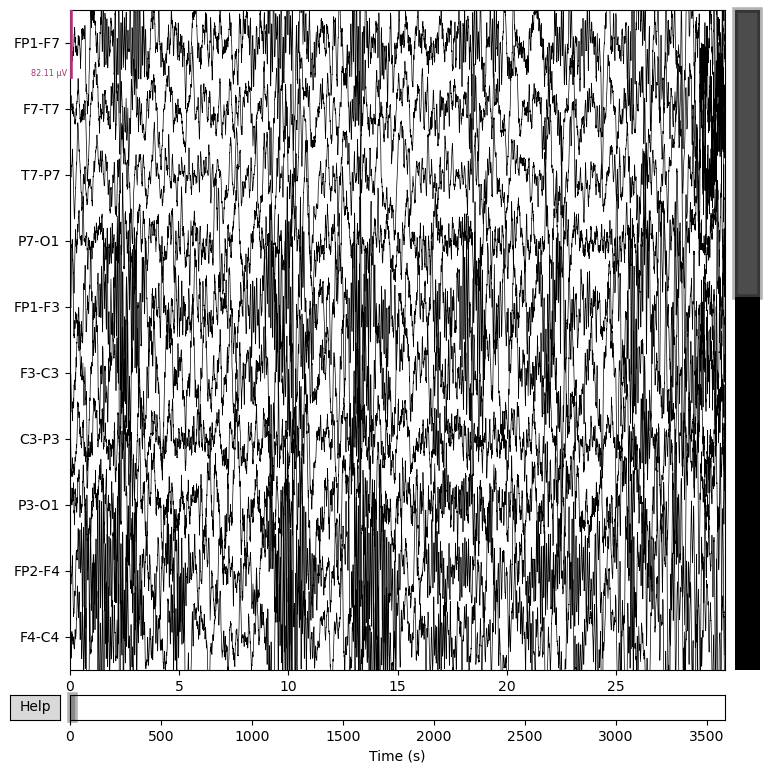

In [17]:
# Plot the first 30 seconds
fig = raw.plot(
    start=0,           # Start at beginning of the plot
    duration=30,       # Show 30 seconds
    n_channels=10,     # Show 10 channels at a time
    scalings='auto',
    title='Patient chb01 with Normal Brain Activity (first 30 seconds)'
)

In [18]:
def get_seizure_times(summary_file):
    seizures = []
    current_file = None 
    current_seizure = {}
    
    # Opening the summary text 
    with open(summary_file, 'r') as f:
        # Loop through the file one line at a time
        for line in f:
            line = line.strip()
            
            # Look for file name
            if line.startswith('File Name:'):
                current_file = line.split(':')[1].strip()
            
            # Look for seizure start
            elif line.startswith('Seizure Start Time:'):
                start_time = int(line.split(':')[1].strip().split()[0])
                current_seizure['start'] = start_time
                current_seizure['file'] = current_file
            
            # Look for seizure end
            elif line.startswith('Seizure End Time:'):
                end_time = int(line.split(':')[1].strip().split()[0])
                current_seizure['end'] = end_time
                
                # Add complete seizure to list
                if 'start' in current_seizure and 'file' in current_seizure:
                    seizures.append(current_seizure.copy())
                    current_seizure = {}
    
    return seizures

summary_file = '../data/chb01/chb01-summary.txt'

# Test it
seizures = get_seizure_times(summary_file)
print(f"Found {len(seizures)} seizures")
for i, sz in enumerate(seizures, 1):
    print(f"Seizure {i}: File {sz['file']}, {sz['start']}-{sz['end']} seconds")

Found 7 seizures
Seizure 1: File chb01_03.edf, 2996-3036 seconds
Seizure 2: File chb01_04.edf, 1467-1494 seconds
Seizure 3: File chb01_15.edf, 1732-1772 seconds
Seizure 4: File chb01_16.edf, 1015-1066 seconds
Seizure 5: File chb01_18.edf, 1720-1810 seconds
Seizure 6: File chb01_21.edf, 327-420 seconds
Seizure 7: File chb01_26.edf, 1862-1963 seconds


In [19]:


# Get the first seizure
first_seizure = seizures[0]  # This gets seizure #2
print(f"\nTargeting: {first_seizure['file']}")
print(f"Seizure occurs at: {first_seizure['start']}-{first_seizure['end']} seconds")

# Load that specific file
eeg_file = f"../data/chb01/{first_seizure['file']}"
print(f"\nLoading: {eeg_file}")

raw = mne.io.read_raw_edf(eeg_file, preload=True, verbose=False)


print(f"  Duration: {raw.times[-1]/60:.1f} minutes")
print(f"  Channels: {len(raw.ch_names)}")
print(f"  Sampling rate: {raw.info['sfreq']} Hz")

# Show the seizure window
seizure_start_samples = int(first_seizure['start'] * raw.info['sfreq'])
seizure_end_samples = int(first_seizure['end'] * raw.info['sfreq'])

print(f"  Starts at sample: {seizure_start_samples}")
print(f"  Ends at sample: {seizure_end_samples}")

print("="*60)


Targeting: chb01_03.edf
Seizure occurs at: 2996-3036 seconds

Loading: ../data/chb01/chb01_03.edf
  Duration: 60.0 minutes
  Channels: 23
  Sampling rate: 256.0 Hz
  Starts at sample: 766976
  Ends at sample: 777216


/var/folders/rk/w0plzk6n4033x_g087swl6t40000gn/T/ipykernel_52744/767025369.py:10: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(eeg_file, preload=True, verbose=False)



Plotting from 2936s to 3096s
Seizure: 2996s to 3036s
Preictal: 1196s to 2996s


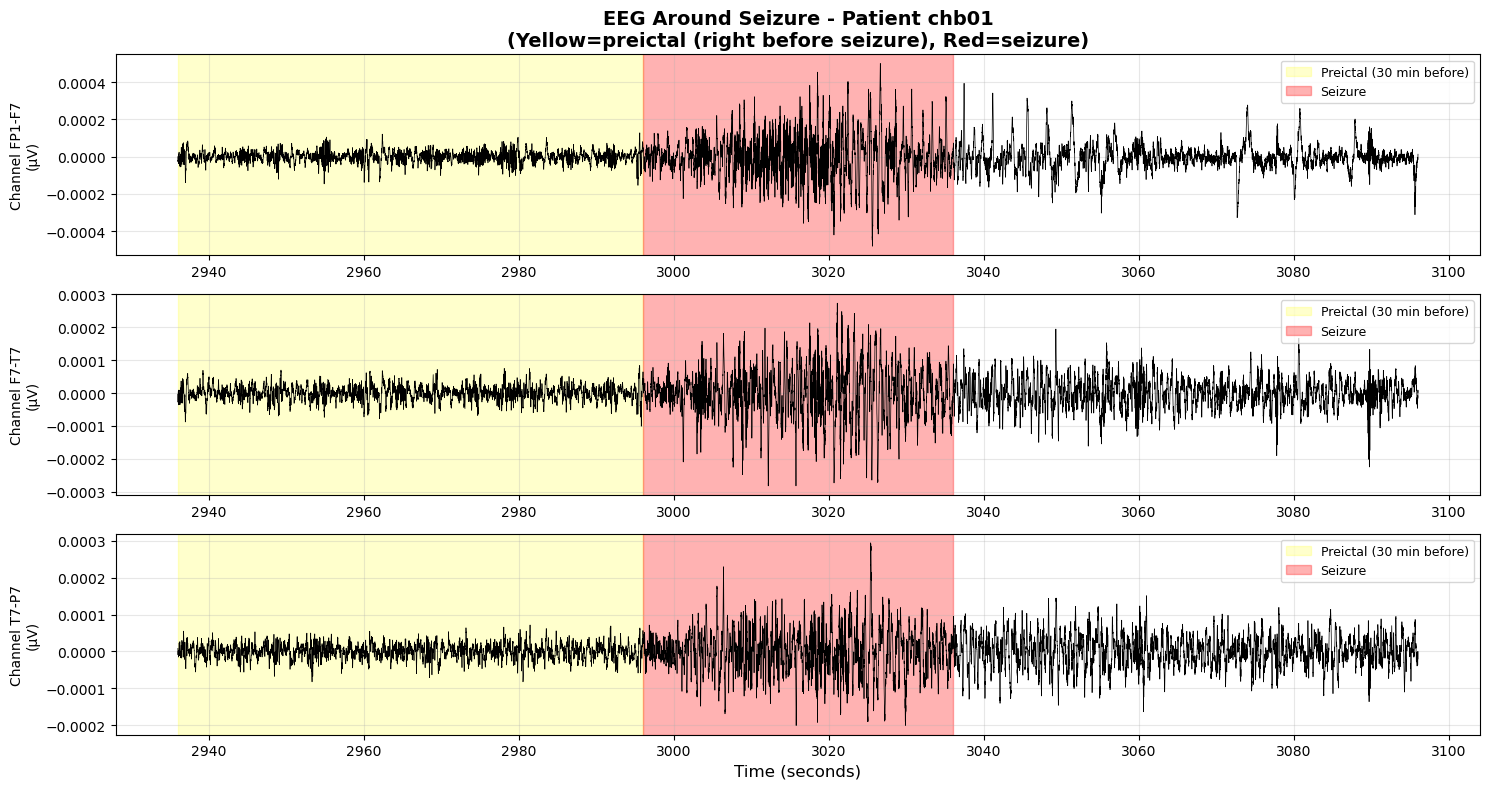

In [33]:
import matplotlib.pyplot as plt

# Get data
data = raw.get_data()
times = raw.times

# Get seizure location
sz_start_sec = first_seizure['start']
sz_end_sec = first_seizure['end']

preictal_start = sz_start_sec - 30*60  # 30 minutes before seizure

# Plot 2 minutes around the seizure
plot_start = max(0, sz_start_sec - 60)  # 1 min before seizure
plot_end = min(times[-1], sz_end_sec + 60)  # 1 min after seizure

print(f"\nPlotting from {plot_start:.0f}s to {plot_end:.0f}s")
print(f"Seizure: {sz_start_sec:.0f}s to {sz_end_sec:.0f}s")
print(f"Preictal: {preictal_start:.0f}s to {sz_start_sec:.0f}s")

plot_start_idx = int(plot_start * raw.info['sfreq'])
plot_end_idx = int(plot_end * raw.info['sfreq'])

# Use first 3 channels
fig, axes = plt.subplots(3, 1, figsize=(15, 8))

for i in range(3):
    axes[i].plot(
        times[plot_start_idx:plot_end_idx], 
        data[i, plot_start_idx:plot_end_idx],
        color='black',
        linewidth=0.5
    )
    
    preictal_display_start = max(preictal_start, plot_start)
    preictal_display_end = sz_start_sec
    
    if preictal_display_start < preictal_display_end:
        axes[i].axvspan(preictal_display_start, preictal_display_end,
                         color='yellow', alpha=0.2,
                         label='Preictal (30 min before)')
    
    # Highlight seizure period in red
    seizure_display_start = max(sz_start_sec, plot_start)
    seizure_display_end = min(sz_end_sec, plot_end)
    
    if seizure_display_start < seizure_display_end:
        axes[i].axvspan(seizure_display_start, seizure_display_end,
                         color='red', alpha=0.3,
                         label='Seizure')
    
    axes[i].set_ylabel(f'Channel {raw.ch_names[i]}\n(μV)', fontsize=10)
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(loc='upper right', fontsize=9)  # Show legend on all subplots
    
    if i == 0:
        axes[i].set_title('EEG Around Seizure - Patient chb01\n(Yellow=preictal (right before seizure), Red=seizure)', 
                          fontsize=14, fontweight='bold')

axes[-1].set_xlabel('Time (seconds)', fontsize=12)

plt.tight_layout()
plt.savefig('seizure_visualization.png', dpi=150, bbox_inches='tight')

plt.show()


In [24]:

# Get the seizure info
sz_start_sec = first_seizure['start']
sz_end_sec = first_seizure['end']

# Define time windows
baseline_start = 600   # 10 minutes into recording (normal baseline)
baseline_end = 720     # 12 minutes (2-minute window)

preictal_start = sz_start_sec - 180  # 3 minutes before seizure
preictal_end = sz_start_sec           # up to seizure start

print(f"\nAnalyzing channel: {raw.ch_names[0]}")
print(f"Baseline window: {baseline_start}-{baseline_end} sec (normal activity)")
print(f"Preictal window: {preictal_start}-{preictal_end} sec (before seizure)")

# Convert to sample indices
sfreq = raw.info['sfreq']
baseline_start_idx = int(baseline_start * sfreq)
baseline_end_idx = int(baseline_end * sfreq)
preictal_start_idx = int(preictal_start * sfreq)
preictal_end_idx = int(preictal_end * sfreq)

# Get data from first channel
data = raw.get_data()
baseline_data = data[0, baseline_start_idx:baseline_end_idx]
preictal_data = data[0, preictal_start_idx:preictal_end_idx]

# Feature extraction function
def extract_wearable_features(eeg_signal, sfreq):
    """
    Extract features that CORRELATE with what wearables measure.
    Not extracting actual wearable signals - extracting EEG patterns 
    that correlate with autonomic/movement activity.
    """
    
    # Compute power spectral density
    f, pxx = signal.welch(eeg_signal, sfreq, nperseg=min(1024, len(eeg_signal)))
    
    # Feature : High-frequency power (>20 Hz)
    high_freq_power = np.sum(pxx[f >= 20])
    
    # Feature : Line length (signal variability)
    line_length = np.sum(np.abs(np.diff(eeg_signal)))
    
    # Feature : Signal entropy (complexity/disorder)
    # Higher entropy means a more irregular physiological state
    hist, _ = np.histogram(eeg_signal, bins=50)
    hist = hist / np.sum(hist)
    signal_entropy = entropy(hist + 1e-10)
    
    
    return {
        'high_freq_power': high_freq_power,
        'line_length': line_length,
        'entropy': signal_entropy,
    }

# Extract features
baseline_features = extract_wearable_features(baseline_data, sfreq)
preictal_features = extract_wearable_features(preictal_data, sfreq)

print("EXTRACTED FEATURES:")

print("\n BASELINE (Normal Activity occurring way before the seizure (normal brain state):")
for feature, value in baseline_features.items():
    print(f"  {feature:20s}: {value:12.2e}")

print("\n  PREICTAL (Before Seizure):")
for feature, value in preictal_features.items():
    print(f"  {feature:20s}: {value:12.2e}")


print("\n PERCENT CHANGE FROM BASELINE:")
for feature in baseline_features.keys():
    baseline_val = baseline_features[feature]
    preictal_val = preictal_features[feature]
    pct_change = ((preictal_val - baseline_val) / baseline_val) * 100
    
    direction = " INCREASED" if pct_change > 0 else " DECREASED"
    print(f"  {feature:20s}: {direction:12s} {abs(pct_change):6.1f}%")




Analyzing channel: FP1-F7
Baseline window: 600-720 sec (normal activity)
Preictal window: 2816-2996 sec (before seizure)
EXTRACTED FEATURES:

 BASELINE (Normal Activity occurring way before the seizure (normal brain state):
  high_freq_power     :     5.58e-11
  line_length         :     1.48e-01
  entropy             :     2.90e+00

  PREICTAL (Before Seizure):
  high_freq_power     :     4.79e-11
  line_length         :     1.82e-01
  entropy             :     2.40e+00

 PERCENT CHANGE FROM BASELINE:
  high_freq_power     :  DECREASED     14.2%
  line_length         :  INCREASED     23.5%
  entropy             :  DECREASED     17.4%


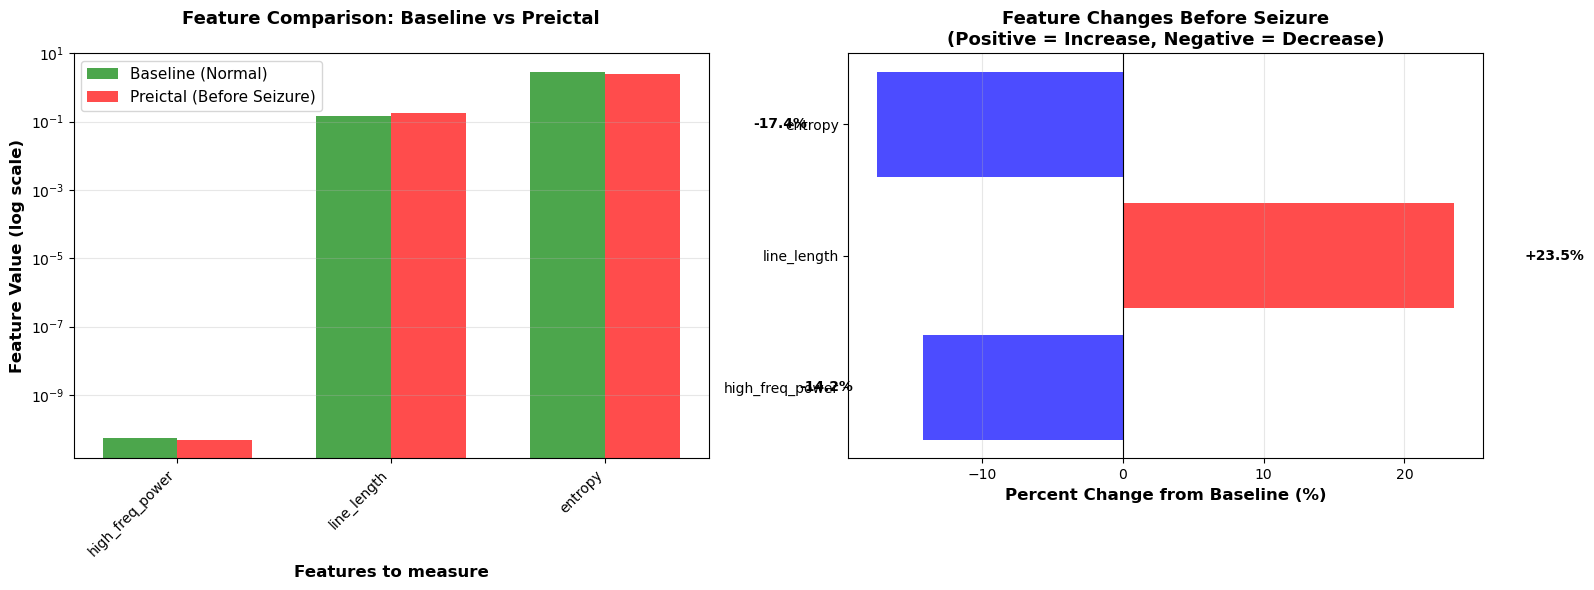


(How much did the features change from baseline to preictal (right before seizure))

I'm extracting features from the preictal period, since I am trying to predict a seizure. 

FEATURE CHANGES: BASELINE TO PREICTAL PERIOD

I extracted three EEG features (entropy, line_length and compared values from a 2-minute 
baseline window (10-12 minutes into recording) to a 30-minute preictal 
window ( right before seizure occuring).

Entropy: -17.4% Decrease 
Entropy is a measure of signal randomness (irregular complex patterns means high entropy)
Entropy decreased by 17.4% from baseline to preictal period. This means that there was a decrease in brain signal 
entropy. This is normal and expected. During an epileptic seizure, neurons fire in synchronized 
patterns, so complexity drops and therefore entropy decreases. 

Line length: +23.5% Increase 
Line length - how much the signal travels up and down, correlates with overall physiological 
activity level, state transitions (rest to awake). (Hig

In [23]:
import matplotlib.pyplot as plt

# Prepare data
features = list(baseline_features.keys())
baseline_vals = [baseline_features[f] for f in features]
preictal_vals = [preictal_features[f] for f in features]

# Create comparison plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Bar chart comparison
x = np.arange(len(features))
width = 0.35

ax = axes[0]
bars1 = ax.bar(x - width/2, baseline_vals, width, 
               label='Baseline (Normal)', color='green', alpha=0.7)
bars2 = ax.bar(x + width/2, preictal_vals, width, 
               label='Preictal (Before Seizure)', color='red', alpha=0.7)

ax.set_xlabel('Features to measure', fontsize=12, fontweight='bold')
ax.set_ylabel('Feature Value (log scale)', fontsize=12, fontweight='bold')
ax.set_title('Feature Comparison: Baseline vs Preictal\n', 
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(features, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.set_yscale('log')
ax.grid(True, alpha=0.3, axis='y')

# Right plot: Percent change
ax = axes[1]
pct_changes = []
for feature in features:
    baseline_val = baseline_features[feature]
    preictal_val = preictal_features[feature]
    pct_change = ((preictal_val - baseline_val) / baseline_val) * 100
    pct_changes.append(pct_change)

colors = ['red' if x > 0 else 'blue' for x in pct_changes]
bars = ax.barh(features, pct_changes, color=colors, alpha=0.7)

ax.set_xlabel('Percent Change from Baseline (%)', fontsize=12, fontweight='bold')
ax.set_title('Feature Changes Before Seizure\n(Positive = Increase, Negative = Decrease)', 
             fontsize=13, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.grid(True, alpha=0.3, axis='x')

# Adding value labels
for i, (bar, val) in enumerate(zip(bars, pct_changes)):
    ax.text(val + (5 if val > 0 else -5), i, f'{val:+.1f}%', 
            va='center', ha='left' if val > 0 else 'right', fontweight='bold')

plt.tight_layout()
plt.savefig('feature_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
(How much did the features change from baseline to preictal (right before seizure))

I'm extracting features from the preictal period, since I am trying to predict a seizure. 

FEATURE CHANGES: BASELINE TO PREICTAL PERIOD

I extracted three EEG features (entropy, line_length and compared values from a 2-minute 
baseline window (10-12 minutes into recording) to a 30-minute preictal 
window ( right before seizure occuring).

Entropy: -17.4% Decrease 
Entropy is a measure of signal randomness (irregular complex patterns means high entropy)
Entropy decreased by 17.4% from baseline to preictal period. This means that there was a decrease in brain signal 
entropy. This is normal and expected. During an epileptic seizure, neurons fire in synchronized 
patterns, so complexity drops and therefore entropy decreases. 

Line length: +23.5% Increase 
Line length - how much the signal travels up and down, correlates with overall physiological 
activity level, state transitions (rest to awake). (High line length = active brain state, 
low line length = stable signal = quiet brain state
Line length increased by 23.5% from baseline to preictal period, indicating 
increased signal variability and amplitude. As seen in visualizing the seizure, 
(the red portion of the graph), the amplitude of the brain waves become much bigger than usual,
corresponding to a seizure. Line length increasing during a seizure is normal. 

High-frequency power: -14.2% Decrease 
High-frequency power decreased by 14.2% from baseline to preictal period. 
This is unexpected, but could have a few explanations, such as that damaged
brain regions are temporarily losing their connectivity. 

I'm trying to find a minimal amount of features that can predict a seizure. 

""")
